# 03 - Bike Sharing Demand (hourly rentals)
**Topic:** Regression  |  **Source:** UCI Bike Sharing (Washington D.C., 2011-2012), loaded from OpenML
**Reference solution:** none (not on either list; it replaces Concrete Strength, which repeated Homework-Day5). I compare against a **ladder of simpler models** instead.

**Question.** How many bikes will be rented in a given hour, from the hour of day, day type and weather forecast? A bike-share operator needs this to place and rebalance bikes.

**What makes it interesting:** the target is a *count* with strong daily rhythm, a growth trend between the two years, and weather effects. And because the real use is forecasting the *future*, I split **by time** (train on the past, test on the final three months) instead of randomly.

## 1. Libraries and data

In [1]:
import warnings, os, json, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler
from sklearn.linear_model import PoissonRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_log_error, mean_poisson_deviance
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("model", exist_ok=True)
cache = "../_data/bike.csv"
raw = pd.read_csv(cache) if os.path.exists(cache) else fetch_openml(data_id=42712, as_frame=True, parser="auto").frame
raw.to_csv(cache, index=False)
df = raw.copy()
for c in ["holiday", "workingday"]:
    df[c] = df[c].astype(str).eq("True").astype(int)
df["year"] = df["year"] + 2011
df = df.drop(columns="season")        # the file's season labels do not match the calendar (January is labelled 'spring'); month carries the information
print(df.shape); df.head()

(17379, 12)


,year,month,hour,holiday,weekday,workingday,weather,temp,feel_temp,humidity,windspeed,count
0,2011,1,0,0,6,0,clear,9.84,14.395,0.81,0.0,16
1,2011,1,1,0,6,0,clear,9.02,13.635,0.80,0.0,40
2,2011,1,2,0,6,0,clear,9.02,13.635,0.80,0.0,32
3,2011,1,3,0,6,0,clear,9.84,14.395,0.75,0.0,13
4,2011,1,4,0,6,0,clear,9.84,14.395,0.75,0.0,1


**Columns.** `year`, `month`, `hour` (0-23), `weekday` (0-6), `holiday`, `workingday`, `weather` (clear / misty / rain / heavy_rain), `temp` and `feel_temp` (deg C), `humidity` (0-1), `windspeed`, and `count` (bikes rented that hour). I dropped `season`: January rows are labelled "spring", so it contradicts the calendar and `month` already says the same thing.

## 2. Look at the data first

In [2]:
print("missing:", int(df.isna().sum().sum()), "| rows:", len(df), "| possible hours in 2 years:", 731 * 24, "(so some hours are missing from the log)")
print(df["count"].describe().round(1).to_dict())
print("share of hours with count < 10: %.1f%%" % ((df["count"] < 10).mean() * 100))
print(df.groupby("weather")["count"].agg(["size", "mean"]).round(1).to_string())

missing: 0 | rows: 17379 | possible hours in 2 years: 17544 (so some hours are missing from the log)
{'count': 17379.0, 'mean': 189.5, 'std': 181.4, 'min': 1.0, '25%': 40.0, '50%': 142.0, '75%': 281.0, 'max': 977.0}
share of hours with count < 10: 10.5%
             size   mean
weather                 
clear       11413  204.9
heavy_rain      3   74.3
misty        4544  175.2
rain         1419  111.6


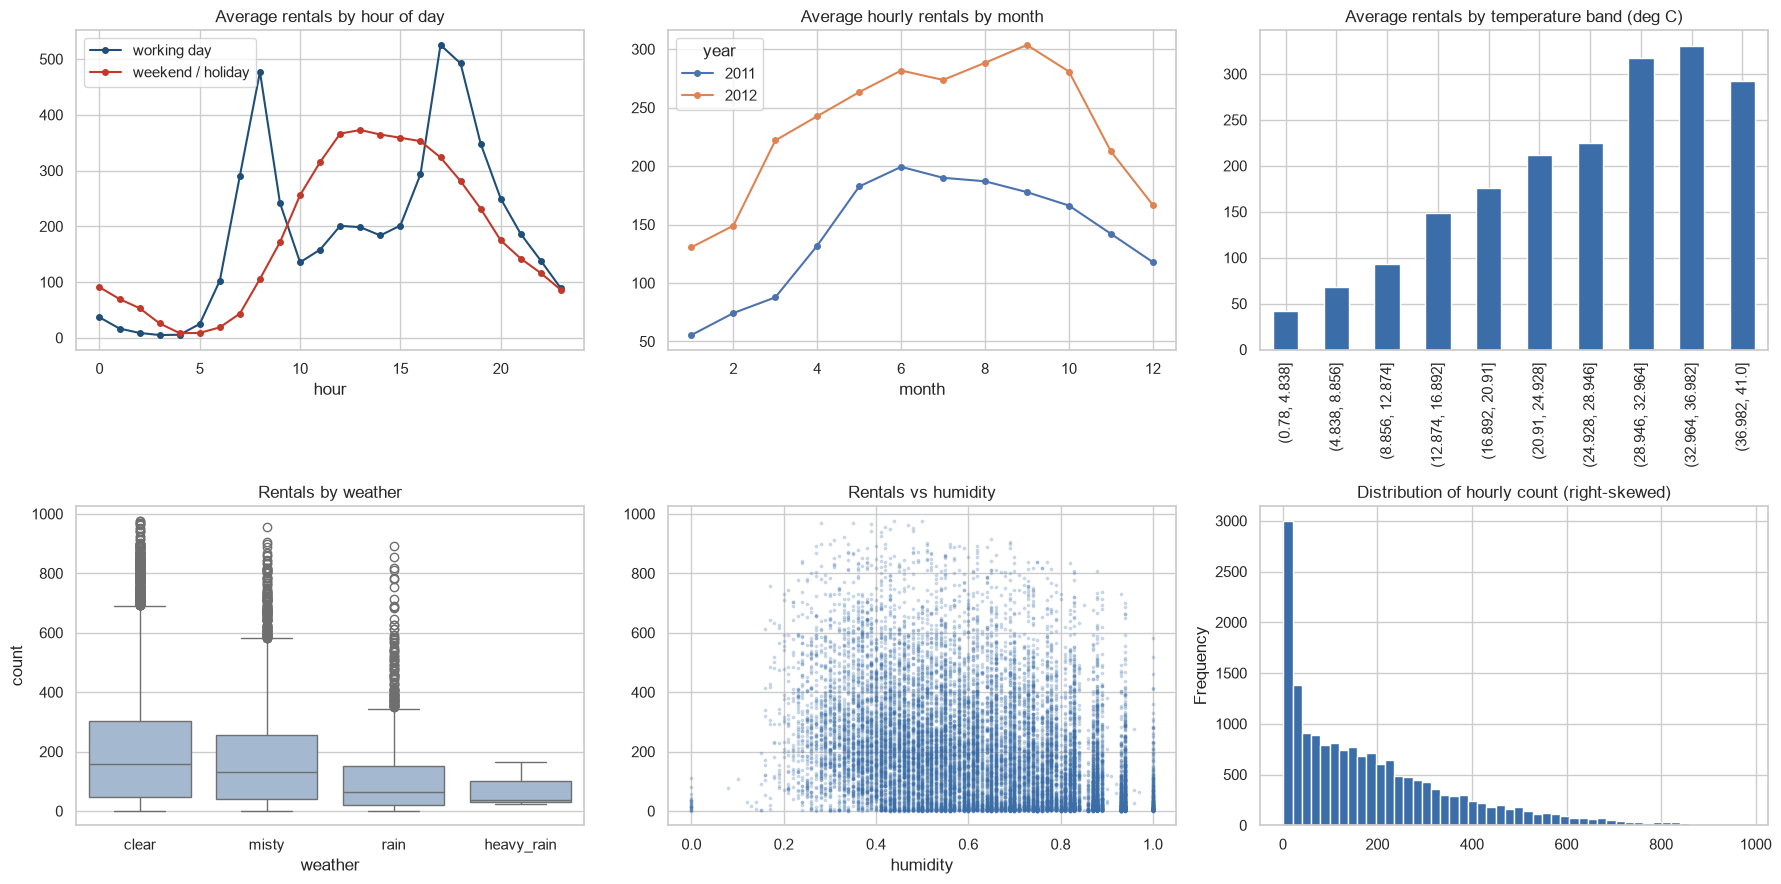

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
for wd, lab, col in [(1, "working day", "#1f4e79"), (0, "weekend / holiday", "#c0392b")]:
    s = df[df.workingday == wd].groupby("hour")["count"].mean(); ax[0, 0].plot(s.index, s.values, marker="o", ms=4, label=lab, color=col)
ax[0, 0].set_title("Average rentals by hour of day"); ax[0, 0].set_xlabel("hour"); ax[0, 0].legend()
m = df.groupby(["year", "month"])["count"].mean().unstack(0); m.plot(ax=ax[0, 1], marker="o", ms=4); ax[0, 1].set_title("Average hourly rentals by month"); ax[0, 1].set_xlabel("month")
df.assign(tb=pd.cut(df.temp, 10)).groupby("tb", observed=True)["count"].mean().plot.bar(ax=ax[0, 2], color="#3b6ea8"); ax[0, 2].set_title("Average rentals by temperature band (deg C)"); ax[0, 2].set_xlabel("")
sns.boxplot(data=df, x="weather", y="count", ax=ax[1, 0], color="#9db8d6"); ax[1, 0].set_title("Rentals by weather")
ax[1, 1].scatter(df.humidity, df["count"], s=3, alpha=.2, color="#3b6ea8"); ax[1, 1].set_title("Rentals vs humidity"); ax[1, 1].set_xlabel("humidity")
df["count"].plot.hist(bins=50, ax=ax[1, 2], color="#3b6ea8"); ax[1, 2].set_title("Distribution of hourly count (right-skewed)")
plt.tight_layout(); plt.show()

**Reading it.**
* **Two different daily rhythms.** On working days there are two sharp peaks (about 8:00 and 17:00-18:00, roughly 480-520 rentals per hour on average), the shape of commuting. On weekends and holidays there is one broad hump around midday and early afternoon (about 370). A model must know the day type, not just the hour.
* **Growth and seasonality.** Every month of 2012 is busier than the same month of 2011, and both years peak in summer/early autumn and dip in winter.
* **Weather.** Rentals rise steadily with temperature (to about 33 deg C, then flatten), are lower in rain, and "heavy_rain" has only **3 rows**, so nothing reliable can be said about it.
* About 10% of hours have fewer than 10 rentals (mostly the night) and the count is strongly right-skewed: this is why count-style losses (Poisson) and relative-error metrics (RMSLE) are used.
* These patterns are associations in the log, not tested causes.

## 3. Time-ordered split
Train: all of 2011 plus January-September 2012. Test: October-December 2012 (the final quarter). Hours are ordered in time, so no test hour is earlier than a training hour.

In [4]:
test_mask = (df.year == 2012) & (df.month >= 10)
tr, te = df[~test_mask].copy(), df[test_mask].copy()
print(len(tr), "train rows |", len(te), "test rows")
print("mean hourly count: train %.0f | test %.0f" % (tr["count"].mean(), te["count"].mean()))
num = ["temp", "feel_temp", "humidity", "windspeed"]
cat = ["hour", "weekday", "month", "weather"]
F = ["year", "hour", "weekday", "month", "holiday", "workingday", "weather"] + num
def rmsle(y, p): return float(np.sqrt(mean_squared_log_error(y, np.clip(p, 0, None))))
def scores(p): return dict(RMSLE=rmsle(te["count"], p), MAE=mean_absolute_error(te["count"], p), PoissonDev=mean_poisson_deviance(te["count"], np.clip(p, 1e-3, None)))

15211 train rows | 2168 test rows
mean hourly count: train 185 | test 219


**Reading it.** The test quarter is busier than the training average (219 vs 185 bikes per hour): the system was still growing. A forward test is therefore harder than a random one, and that is the realistic situation.

## 4. Model ladder
Metrics on the held-out quarter: **RMSLE** (error in relative terms; the usual metric for this problem), **MAE** (bikes per hour) and Poisson deviance.
1. **Hour x working-day average** - no model: "what usually happens at this hour on this kind of day".
2. **Poisson GLM** - one-hot calendar terms, an hour x working-day interaction, splines for weather numbers, a year term.
3. **Random forest** and 4. **Gradient boosting** (Poisson loss) - on the raw features.
5. **Gradient boosting, log target** - squared error on log(1+count).

In [5]:
base = tr.groupby(["hour", "workingday"])["count"].mean()
p_base = te.set_index(["hour", "workingday"]).index.map(base).to_numpy()

tr["yr01"] = tr.year - 2011; te["yr01"] = te.year - 2011
tr["hw"] = tr.hour.astype(str) + "_" + tr.workingday.astype(str); te["hw"] = te.hour.astype(str) + "_" + te.workingday.astype(str)
glm = make_pipeline(ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), cat + ["hw"]),
                                       ("s", SplineTransformer(n_knots=6, degree=3), num),
                                       ("p", "passthrough", ["yr01", "holiday", "workingday"])]), PoissonRegressor(alpha=1e-3, max_iter=1000))
glm.fit(tr[cat + ["hw"] + num + ["yr01", "holiday", "workingday"]], tr["count"])
p_glm = glm.predict(te[cat + ["hw"] + num + ["yr01", "holiday", "workingday"]])

def enc(d):
    x = d[F].copy(); x["weather"] = x["weather"].astype("category").cat.set_categories(sorted(df.weather.unique())); return x
rf = RandomForestRegressor(400, min_samples_leaf=3, n_jobs=-1, random_state=0).fit(enc(tr).assign(weather=lambda x: x.weather.cat.codes), tr["count"])
p_rf = rf.predict(enc(te).assign(weather=lambda x: x.weather.cat.codes))

hgb = HistGradientBoostingRegressor(loss="poisson", learning_rate=.05, max_iter=600, max_leaf_nodes=20, min_samples_leaf=20, l2_regularization=1.0, categorical_features="from_dtype", random_state=0).fit(enc(tr), tr["count"])
p_hgb = hgb.predict(enc(te))
hgl = HistGradientBoostingRegressor(loss="squared_error", learning_rate=.05, max_iter=600, max_leaf_nodes=20, min_samples_leaf=20, l2_regularization=1.0, categorical_features="from_dtype", random_state=0).fit(enc(tr), np.log1p(tr["count"]))
p_hgl = np.expm1(hgl.predict(enc(te)))

preds = {"1 hour x working-day average": p_base, "2 Poisson GLM": p_glm, "3 random forest": p_rf, "4 gradient boosting (Poisson loss)": p_hgb, "5 gradient boosting (log target)": p_hgl}
lad = pd.DataFrame({k: scores(v) for k, v in preds.items()}).T
print(lad.round(3).to_string())

                                    RMSLE     MAE  PoissonDev
1 hour x working-day average        0.604  79.950      49.637
2 Poisson GLM                       0.486  46.969      22.879
3 random forest                     0.473  48.700      23.238
4 gradient boosting (Poisson loss)  0.429  45.212      20.556
5 gradient boosting (log target)    0.429  45.237      20.938


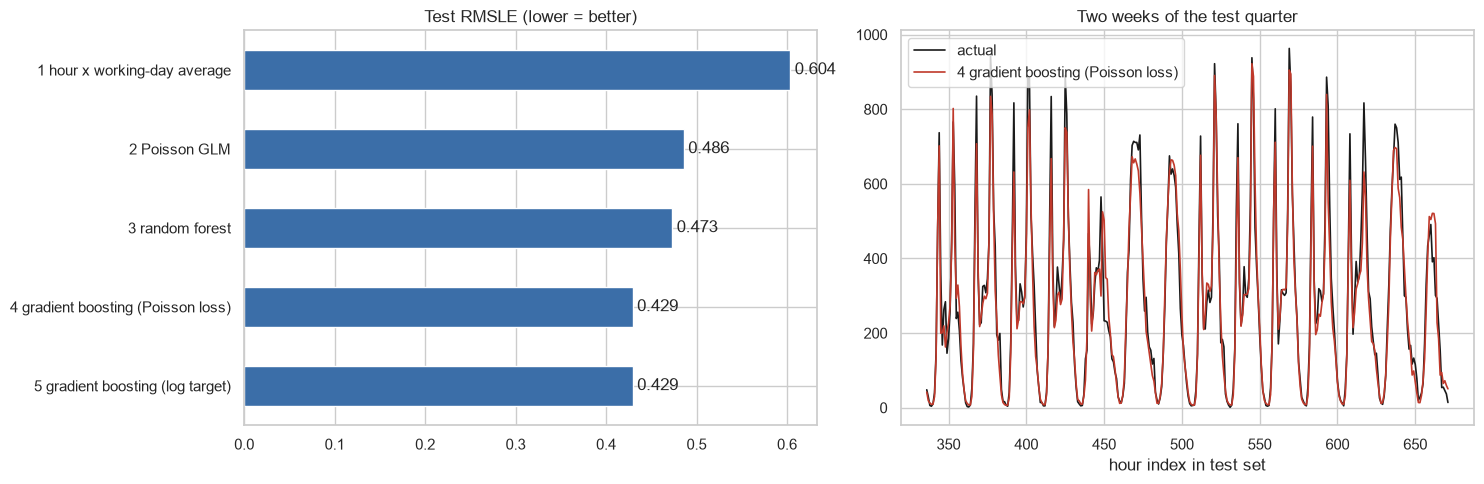

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
lad.RMSLE.iloc[::-1].plot.barh(ax=ax[0], color="#3b6ea8"); ax[0].set_title("Test RMSLE (lower = better)")
for i, v in enumerate(lad.RMSLE.iloc[::-1]): ax[0].text(v + .005, i, f"{v:.3f}", va="center")
best = lad.RMSLE.idxmin(); pb = preds[best]
w = te.reset_index(drop=True).iloc[24 * 14: 24 * 28]
ax[1].plot(w.index, w["count"], color="k", lw=1.2, label="actual"); ax[1].plot(w.index, pd.Series(pb).iloc[w.index].values, color="#c0392b", lw=1.2, label=best)
ax[1].set_title("Two weeks of the test quarter"); ax[1].set_xlabel("hour index in test set"); ax[1].legend()
plt.tight_layout(); plt.show()

**Reading it (test quarter, Oct-Dec 2012).**
* The hour x working-day average has RMSLE 0.60 and MAE 80 bikes/hour: it knows the daily rhythm but not weather or growth.
* A Poisson GLM with sensible calendar and weather terms reaches 0.49 / 47 (note: my first version used the raw year 2011/2012 as an input, which broke the fit (RMSLE 1.5) until I rescaled it to 0/1; a reminder that a model's score can hinge on one preprocessing detail).
* Random forest (0.47 / 49) is about as good as the GLM; **gradient boosting is best (0.43 / 45)**, with the Poisson loss and the log-target version essentially tied.
* MAE of about 45 bikes per hour against a mean of 219 is roughly 20% typical error; the commute peaks are the hardest hours (next section).
* Differences between the GLM, forest and boosting on one 2,168-hour test quarter are modest; only the gap to the simple average is large.

## 5. Where does the best model go wrong? Error by hour, and the effect of the growth trend

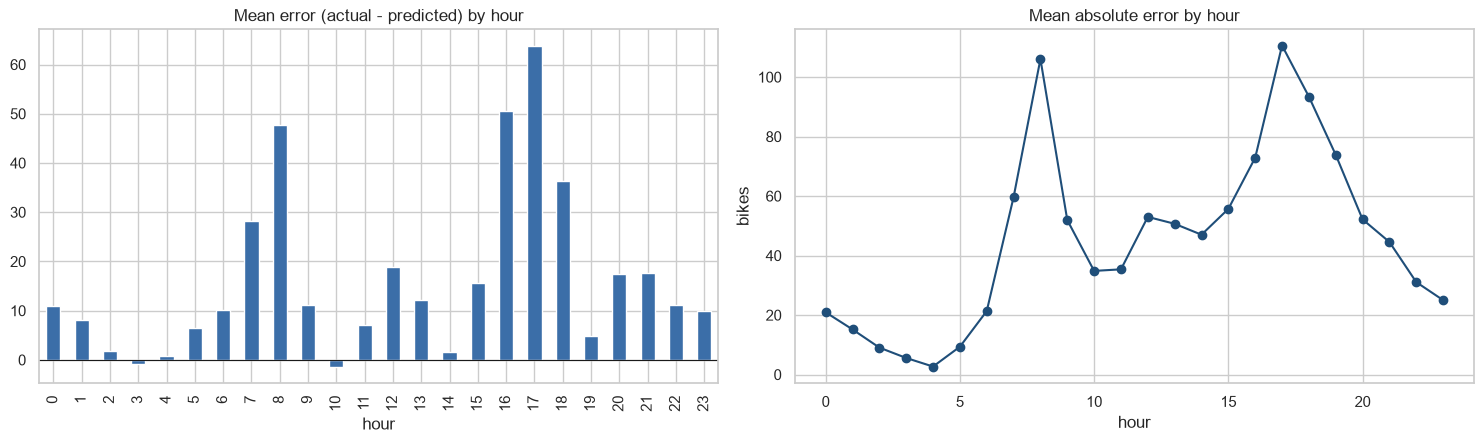

overall mean error (bias): 16.3 bikes/hour; MAE 45.2; mean test count 219

bias by month: {10: 15.2, 11: 23.8, 12: 10.2}


In [7]:
te["pred"] = pb
e = te.assign(err=te["count"] - te.pred)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
e.groupby("hour")["err"].mean().plot.bar(ax=ax[0], color="#3b6ea8"); ax[0].set_title("Mean error (actual - predicted) by hour"); ax[0].axhline(0, color="k", lw=.8)
e.groupby(["hour"]).apply(lambda g: np.abs(g.err).mean()).plot(ax=ax[1], color="#1f4e79", marker="o"); ax[1].set_title("Mean absolute error by hour"); ax[1].set_ylabel("bikes")
plt.tight_layout(); plt.show()
print("overall mean error (bias): %.1f bikes/hour; MAE %.1f; mean test count %.0f" % (e.err.mean(), np.abs(e.err).mean(), te["count"].mean()))
print("\nbias by month:", e.groupby("month").err.mean().round(1).to_dict())

**Reading it.** The model **under-predicts** on average (actual minus predicted = +16 bikes per hour, in every one of the three months), and the error is concentrated in the commute peaks: mean absolute error is about 105 bikes at 8:00 and 17:00 but under 25 overnight. The positive bias is consistent with the system still growing faster than the training data suggests; a tree model cannot extrapolate a trend beyond the levels it has seen. In practice one would retrain frequently or model the trend explicitly.

## 6. Ablation: how much does the model lean on the 2011->2012 growth?
Same boosted model with `year` removed. If the score collapses, the model is mostly learning "2012 is busier than 2011".

              RMSLE     MAE  PoissonDev
with year     0.429  45.212      20.556
without year  0.541  85.191      54.685


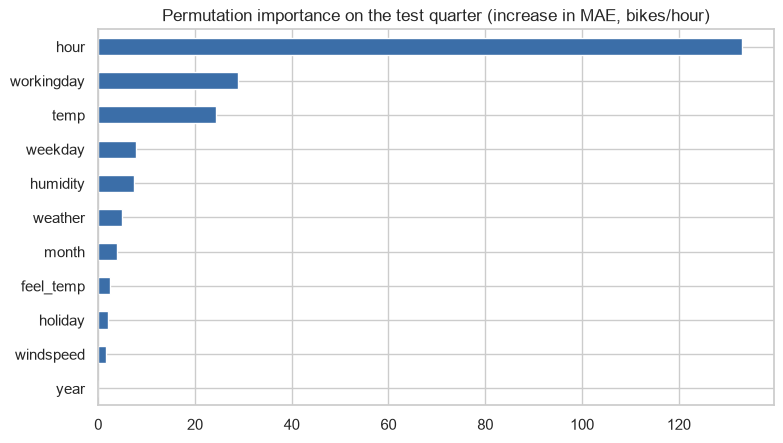

In [8]:
F2 = [c for c in F if c != "year"]
h2 = HistGradientBoostingRegressor(loss="poisson", learning_rate=.05, max_iter=600, max_leaf_nodes=20, min_samples_leaf=20, l2_regularization=1.0, categorical_features="from_dtype", random_state=0).fit(enc(tr)[F2], tr["count"])
p2 = h2.predict(enc(te)[F2])
ab = pd.DataFrame({"with year": scores(p_hgb), "without year": scores(p2)}).T
print(ab.round(3).to_string())
imp = permutation_importance(hgb, enc(te), te["count"], n_repeats=8, random_state=0, scoring="neg_mean_absolute_error")
io = pd.Series(imp.importances_mean, index=F).sort_values()
ax = io.plot.barh(figsize=(8, 4.6), color="#3b6ea8"); ax.set_title("Permutation importance on the test quarter (increase in MAE, bikes/hour)"); plt.tight_layout(); plt.show()

**Reading it.** Without the `year` input the score gets much worse (MAE 45 -> 85, RMSLE 0.43 -> 0.54): the 2011 -> 2012 step in demand is a large effect that the other features cannot reproduce. Permutation importance (right) shows `year` near zero, but that is an artefact: the whole test quarter is 2012, so shuffling `year` inside it changes nothing. The ablation is the more reliable evidence here. By permutation, hour of day dominates, then working day, then temperature.

## 7. How uncertain is one hour? An 80% prediction band
Two boosted models predict the 10th and 90th percentile of the count. A raw band from them is usually too narrow, so I **calibrate** it (split conformal): fit the quantile models on the data before July 2012, measure how far real hours fall outside the band on July-September 2012, and widen the band by the amount that makes 80% of those hours fit. The test quarter is untouched by this step.

In [9]:
core = tr[(tr.year == 2011) | (tr.month < 7)]
cal = tr[(tr.year == 2012) & (tr.month.between(7, 9))]
q = {a: HistGradientBoostingRegressor(loss="quantile", quantile=a, learning_rate=.05, max_iter=500, max_leaf_nodes=20, min_samples_leaf=20, categorical_features="from_dtype", random_state=0).fit(enc(core), core["count"]) for a in (0.1, 0.9)}
lo_c, hi_c = q[0.1].predict(enc(cal)), q[0.9].predict(enc(cal))
score = np.maximum(lo_c - cal["count"].to_numpy(), cal["count"].to_numpy() - hi_c)
n = len(score); Q = float(np.quantile(score, min(1, np.ceil((n + 1) * 0.8) / n)))
lo, hi = q[0.1].predict(enc(te)), q[0.9].predict(enc(te))
raw_cov = ((te["count"] >= lo) & (te["count"] <= hi)).mean()
cover = ((te["count"] >= np.clip(lo - Q, 0, None)) & (te["count"] <= hi + Q)).mean()
print("raw 10-90%% band covers %.1f%% of test hours (target 80%%)" % (raw_cov * 100))
print("calibration widening Q = %.1f bikes -> calibrated band covers %.1f%% of test hours; median width %.0f bikes" % (Q, cover * 100, np.median(hi + Q - np.clip(lo - Q, 0, None))))

raw 10-90% band covers 51.9% of test hours (target 80%)
calibration widening Q = 19.5 bikes -> calibrated band covers 72.6% of test hours; median width 117 bikes


**Reading it.** The raw 10%-90% band covers only 52% of test hours (target 80%): quantile models trained on the past are over-confident about a busier future. The conformal widening (about 19.5 bikes per side, calibrated on July-September 2012) lifts coverage to about 73%, which is better but still below 80%, because the test quarter differs from the calibration quarter (different season, continued growth). The band should be read as "wider than the raw one, still somewhat optimistic".

## 8. Save for the app

In [10]:
final = hgb
joblib.dump({"mean": final, "q10": q[0.1], "q90": q[0.9], "conformal_Q": Q}, "model/bike_models.joblib")
meta = {"features": F, "weather": sorted(df.weather.unique()), "ranges": {c: [float(df[c].min()), float(df[c].max())] for c in num},
        "defaults": {c: float(df[c].median()) for c in num}, "test_scores": lad.round(3).to_dict("index"), "band80_coverage": float(cover), "band80_raw_coverage": float(raw_cov), "conformal_Q": Q}
json.dump(meta, open("model/meta.json", "w"), indent=1)
print(os.listdir("model"))

['bike_models.joblib', 'meta.json']


## 9. Summary
| Step | Result |
|---|---|
| Honest evaluation | time-ordered split: train to Sep 2012, test Oct-Dec 2012 |
| Floor | hour x working-day average: RMSLE 0.60, MAE 80 |
| Best model | gradient boosting (Poisson loss): RMSLE 0.43, MAE 45 bikes/hour |
| Main weakness | under-predicts the growing demand (+16 bikes/hour bias), worst at commute peaks |
| Uncertainty | 80% band covers about 73% of test hours after calibration (raw: 52%) |

**What I learned.** (1) Plot the target by hour and day type before modelling: the whole problem is in those two curves. (2) A forward-in-time split exposes a growth bias a random split would hide. (3) Permutation importance can mislead when a feature barely varies in the evaluation set: confirm with an ablation. (4) Prediction intervals need an explicit coverage check on future data.

**Limits.** Two years of one city; no events/holiday detail beyond a flag; no lag features (yesterday's rentals) because a planner forecasting ahead would not have them. **Next step:** add an explicit trend term or refit weekly, and a separate casual/registered model.